In [6]:
import re
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import (WhisperProcessor, WhisperForConditionalGeneration,
                          MarianMTModel, MarianTokenizer)

audio_file1 = "kirjakieli_neuroverkot.wav"
audio_file2 = "puhekieli_syysaa.wav"
audio_file3 = "taustahälyä_koneoppiminen_v2.wav"

# pip install transformers librosa ipywidgets sentencepiece sacremoses

In [15]:
# Load audio file
y, sr = librosa.load(audio_file2, sr=16000)

# Display audio for playback
print("Play the audio:")
display(Audio(y, rate=sr))

# Print audio statistics
duration = librosa.get_duration(y=y, sr=sr)
print(f"\nAudio Statistics:")
print(f"Duration: {duration:.2f} seconds")
print(f"Sample rate: {sr} Hz")

Play the audio:



Audio Statistics:
Duration: 13.81 seconds
Sample rate: 16000 Hz


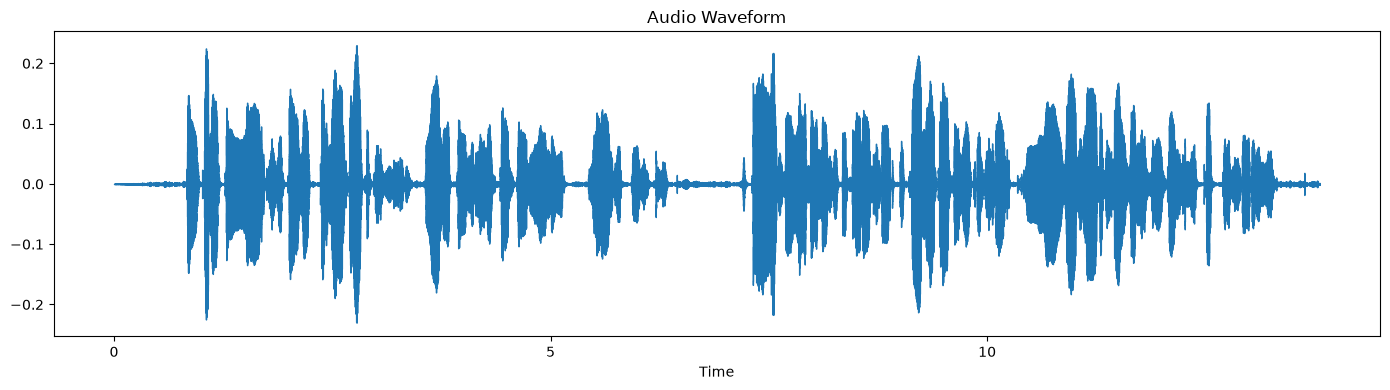

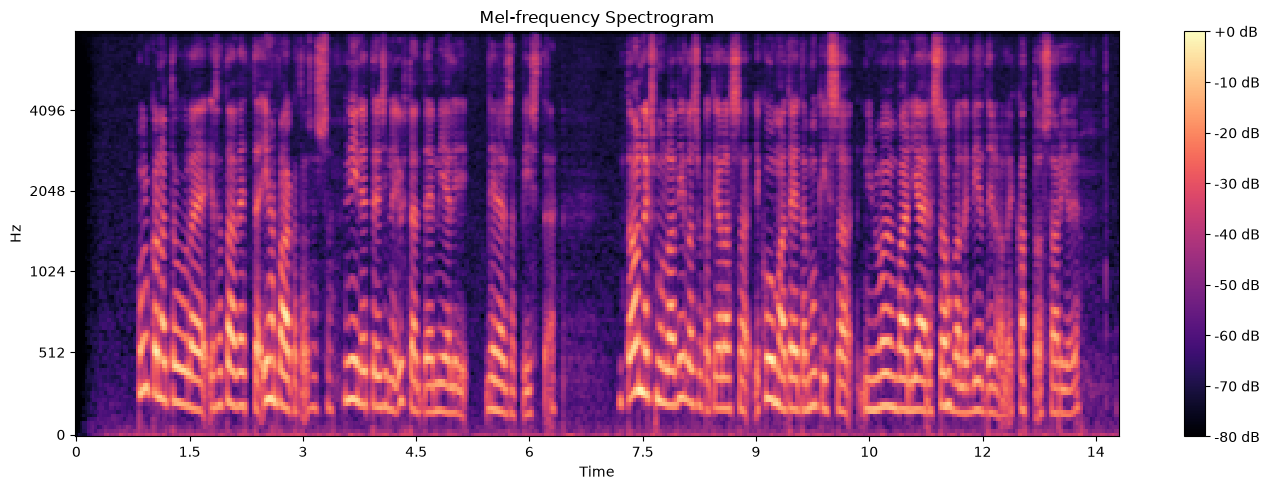

In [16]:
# Plot waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title('Audio Waveform')
plt.tight_layout()
plt.show()

# Create mel spectrogram
plt.figure(figsize=(14, 5))
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr)
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-frequency Spectrogram')
plt.tight_layout()
plt.show()

Ajatuksia:

"Miksi Whisper käyttää mel-spektrogrammia?": 
- Näyttää  ihmisen kuulemaa taajuutta
- Herkkyys matalille taajuuksille, ei näytä korkeapia taajuuksia yhtä herkästi
- x-akseli: aika, y-akseli: taajuus
- Spektogrammi on heatmap: vaaleat väri voimakkaampia/kovempia ääniä, tumma väri hiljaiset/heikot äänet
- Mel-spektogrammi muuttaa äänen "ihmistaajuudelle" --> Tehokkaampi? Puheentunnistus vaatii tajuusalueen joka vastaa ihmisääntä?
  
"Miten tämä liittyy Osan 1 transformer-malliin?":
- Whisper malli koostuu encoder ja decoder Transformer osista
- Encoder muuttaa mel-spektogrammin vektoreiksi
- Decoder ennustaa vektoreiden perusteella tekstiä

Spektogrammien tulkintaa:

Taustahäly:
- Taustahäly sotkee spehtogrammia (ei niis selkeä)
- Tauot eivät näy selkeästi taustahälyn takia
- Tiny malli ei osaa hyvin tunnistaa, medium ja large toimii hyvin

Ei taustahälyä / normaali:
- Tauot puheessa näkyvät selkeästi
- Tiny malli pärjää paremmin, muttei täydellisesti

In [20]:
# Valitse laite: NVIDIA-GPU, Apple-GPU tai CPU
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(f"Using device: {device}")

model_name = "openai/whisper-medium"   # vaihtoehtoja: tiny, base, small, medium, large-v3
processor = WhisperProcessor.from_pretrained(model_name)
model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

# Koko äänite kerralla (truncation=False): Whisper käsittelee 30 s pätkissä ja
# ilman tätä yli 30 s pitkä ääni katkeaisi.
inputs = processor(y, sampling_rate=sr, return_tensors="pt",
                   truncation=False, padding="longest",
                   return_attention_mask=True).to(device, model.dtype)

with torch.no_grad():
    generated_ids = model.generate(**inputs, language="fi", task="transcribe",
                                   return_timestamps=True)   # pakollinen yli 30 s äänelle

transcription = processor.batch_decode(
    generated_ids, skip_special_tokens=True,
    clean_up_tokenization_spaces=False)[0].strip()

print("FINNISH TRANSCRIPTION:")
print("=" * 50)
print(transcription)

Using device: cpu


Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

FINNISH TRANSCRIPTION:
Ulkona tuulee ja sataa vettä ihan vaakatosassa, niin ettei sinne yhtään tee mieli edensä pistää. Mutta onneksi mulla on villasukat jalassa ja kuumaa teetä mukissa, niin voin vain jäädä sohvalle viltin alle kattoossarjoja.


In [21]:
# Suomi -> englanti erillisellä käännösmallilla (Whisperin oma "translate" on huono suomelle).
# Käännetään lause kerrallaan, muuten pitkä teksti katkeaa.
mt_name = "Helsinki-NLP/opus-mt-fi-en"
mt_tokenizer = MarianTokenizer.from_pretrained(mt_name)
mt_model = MarianMTModel.from_pretrained(mt_name)

sentences = re.split(r"(?<=[.?!])\s+", transcription)
batch = mt_tokenizer(sentences, return_tensors="pt", padding=True)
with torch.no_grad():
    out = mt_model.generate(**batch)
translation = " ".join(mt_tokenizer.batch_decode(out, skip_special_tokens=True))

print("ENGLISH TRANSLATION:")
print("=" * 50)
print(translation)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

ENGLISH TRANSLATION:
Outside winds and rains water in the balance, so that there is no desire to advance. But luckily, I'm wearing woolen socks and hot tea in a cup, so I can just stay on the couch under a blanket of ceiling lights.
